In [2]:
from anemone.system import *
from anemone.forwards import Forward, intMat, make_H2t
from anemone import physics, transforms
import matplotlib.pyplot as plt

torch detected, enabling torch tensor support in nosj


In [3]:
t = torch.logspace(-6, -3, 32)
wv = Waveform.example()
tx = Loop.circle(20)
rx = Receiver()

fwr = Forward(tx, rx, t)

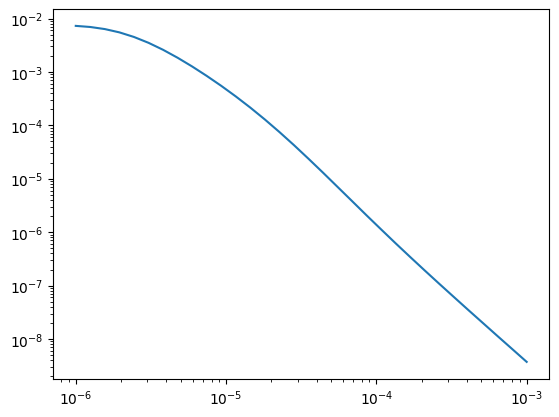

In [4]:
rho,thick = torch.tensor([20, 80, 30]), torch.tensor([20, 20])
dbdt = fwr(rho, thick)

plt.figure()
plt.loglog(fwr.times, dbdt.abs())

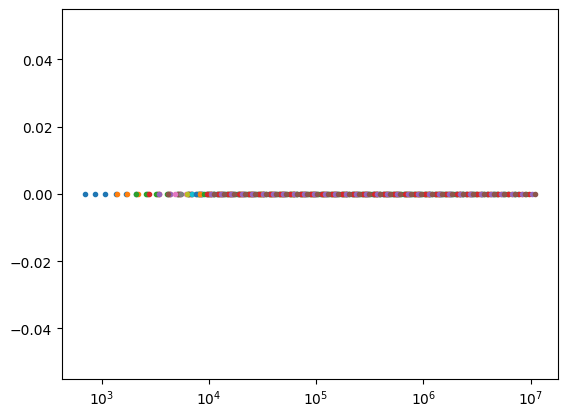

In [5]:
tmpfunc = lambda x: x
ifft = transforms.invFourier(tmpfunc, smp_per_decade=10)
_,__,t_out = ifft.calc_tvals(t.min(), t.max())

t_out = fwr.times

i_lap = (torch.arange(16)+1).to(torch.double)

qit = c.log2*i_lap

s = (qit[None, :] / t_out[:, None])#.flatten()
# s_shp = s.shape
# s = s.flatten()

fig,axs = plt.subplots()
axs.plot(s, s*0., '.')
axs.set_xscale('symlog', linthresh=1e-7)

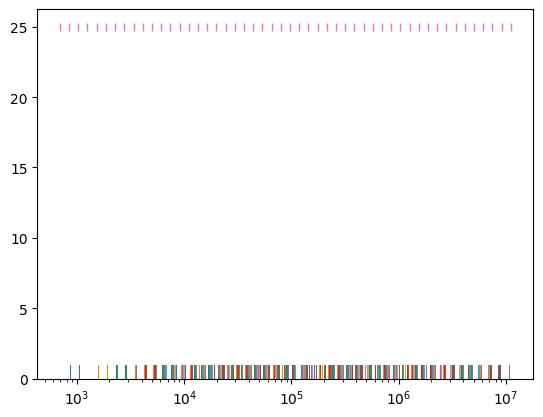

In [6]:
import numpy as np
bins = np.geomspace(s.min(), s.max(), 50)

plt.figure()
plt.hist(s, bins=bins)
plt.plot(bins, 25+bins*0, '|')
plt.xscale('log')

In [7]:
n_decades = round((s.max()/s.min()).log10().item())

print(n_decades)
s_grid = torch.from_numpy(np.geomspace(s.min()/10, s.max()*10, (2+n_decades)*10))
# s_grid = torch.from_numpy(np.geomspace(s.min()/5, s.max()*5, n_decades*10))


4


In [8]:
def intMat(t_in, t_out):
    t_out = t_out.to(t_in.dtype)
    logT = torch.log(t_in)#.cpu()
    dT = logT[1]-logT[0]
    t2t = lamontagne((torch.log(t_out)[:,None]-logT[None,:])/dT)
    return t2t

In [9]:
s.shape

torch.Size([32, 16])

In [10]:
# weights = intMat(s, s_grid).T.reshape(s_shp+s_grid.shape)
#weights = intMat(s_grid, s).reshape(s_shp+s_grid.shape)


weights = (c.log2/t_out[:, None])*transforms.gaver_stehfest_coefficients(16)[None, :]
weights = torch.concatenate([weights, torch.zeros(t.shape+((len(t)-1)*16,))], dim=1)
for i in range(len(t)):
    weights[i] = torch.roll(weights[i], 16*i)


In [11]:
FC = weights

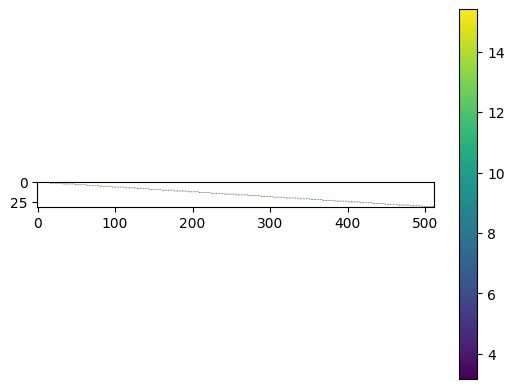

In [12]:
pcm = plt.imshow(FC.log10())
plt.colorbar(pcm)

In [13]:

def make_H2t(t2t, geomz, omega, lmb):
    import numpy as np
    
    H2t = np.zeros(t2t.shape+geomz.shape)

    for i in range(t2t.shape[0]):
        t1 = (t2t[i, :, None]*geomz.real[None, :]).numpy()
        H2t[i] = t1
    H2t = H2t.reshape(t2t.shape[:1]+(-1,))

    Omega,Lambda = np.meshgrid(omega.squeeze().cpu().numpy(), lmb.squeeze().cpu().numpy(), indexing='ij')
    Omega = Omega.flatten()
    Lambda = Lambda.flatten()
    return torch.tensor(H2t), torch.tensor(Omega), torch.tensor(Lambda)

In [14]:
H2t, o_grid, l_grid = make_H2t(FC, fwr.geomz, s.flatten(), fwr.lamda1)
H2t *= c.mu0

In [15]:
H2t.shape

torch.Size([32, 205312])

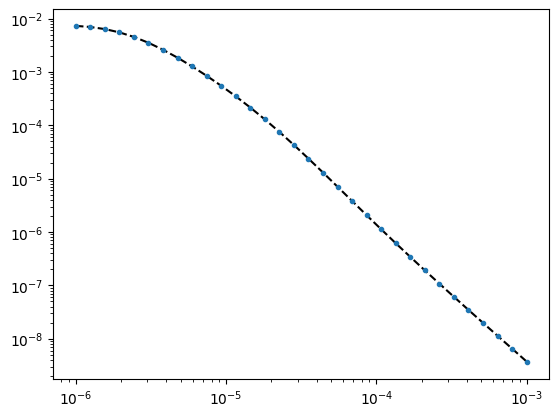

In [16]:
dbdt0 = H2t @ physics.rte_nbc_laplace(1./rho[:, None], thick[:, None], o_grid[None, :], l_grid[None, :]).real.squeeze()
plt.figure()
plt.loglog(fwr.times, dbdt.real.abs(), 'k--')
plt.loglog(fwr.times, dbdt0.abs(), '.')